WEEK 1

In [2]:
print("Hello Digital Signal Processing")

Hello Digital Signal Processing


In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile

plt.rcParams["figure.figsize"]=(9,3.5)
print("DSP Laboratory Setup Successful")


DSP Laboratory Setup Successful


NameError: name 'i' is not defined

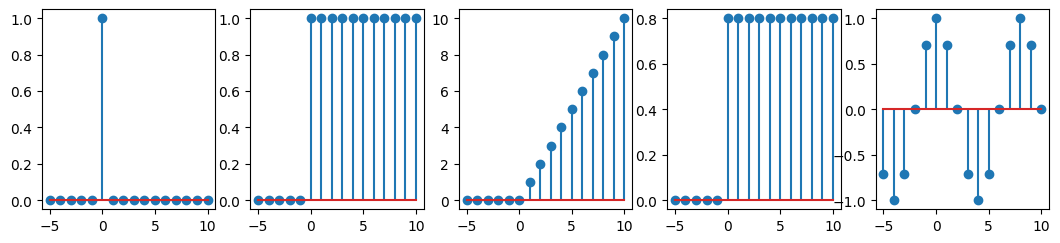

In [21]:
n=np.arange(-5,11)
delta=(n==0).astype(float)#unit impulse
step=(n>=0).astype(float)#unit step
ramp=n*step #unit ram
expo=0.8*step #exponential
fig,axes=plt.subplots(1,5,figsize=(13,2.6))
for ax,x,tittle in zip(
    axes,
    [delta,step,ramp,expo,np.cos(2*np.pi*n/8)],
    ["Impulse","Step","Ramp","Exponential","Cosine"]
):
 ax.stem(n,x)
axes[i].set_title(titles[i])
ax.set_xlabel("n")
ax.grid(True)
plt.tight_layout
plt.show()

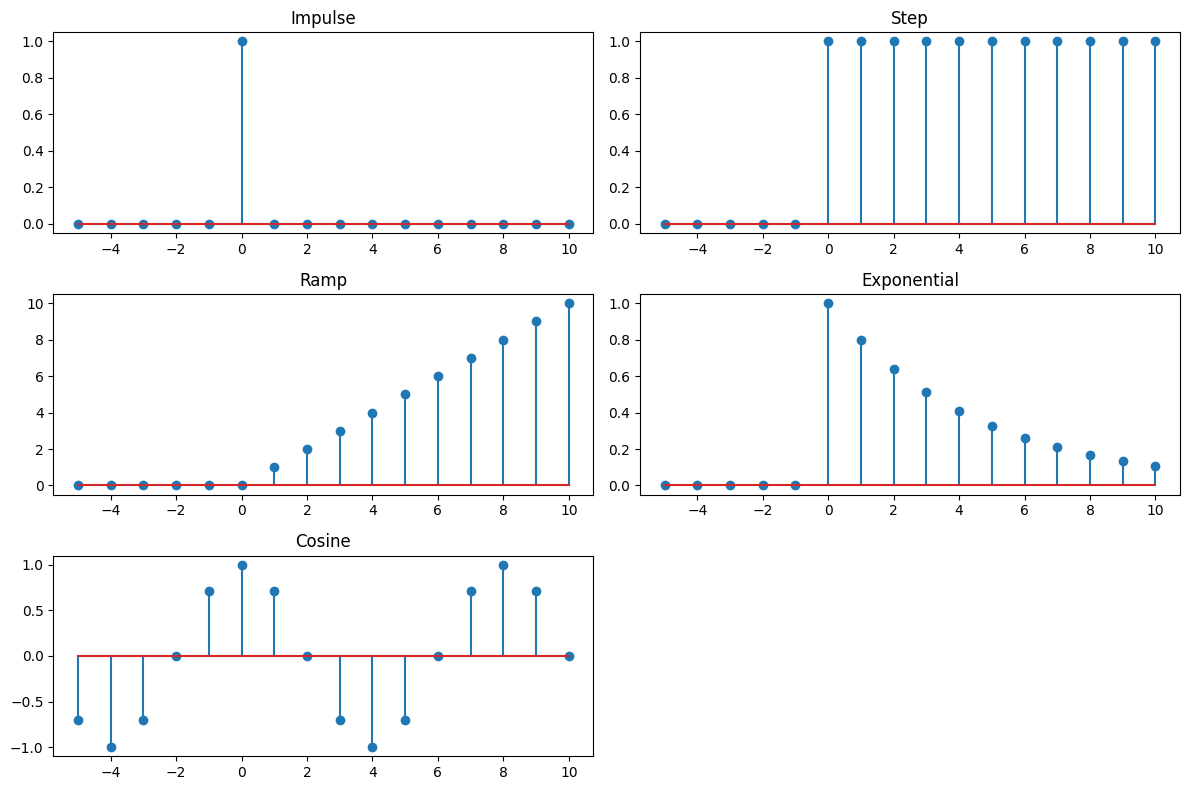

In [22]:
import numpy as np
import matplotlib.pyplot as plt

n = np.arange(-5, 11)

delta = (n == 0).astype(float)
step = (n >= 0).astype(float)
ramp = n * step
expo = 0.8**n * step
cosine = np.cos(2*np.pi*n/8)

plt.figure(figsize=(12, 8))

plt.subplot(3, 2, 1)
plt.stem(n, delta)
plt.title("Impulse")

plt.subplot(3, 2, 2)
plt.stem(n, step)
plt.title("Step")

plt.subplot(3, 2, 3)
plt.stem(n, ramp)
plt.title("Ramp")

plt.subplot(3, 2, 4)
plt.stem(n, expo)
plt.title("Exponential")

plt.subplot(3, 2, 5)
plt.stem(n, cosine)
plt.title("Cosine")

plt.tight_layout()
plt.show()

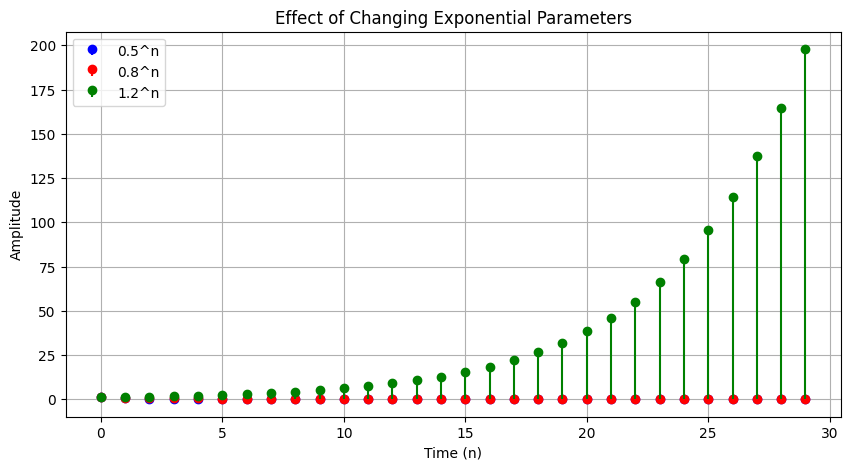

In [23]:
import numpy as np
import matplotlib.pyplot as plt

n = np.arange(0, 30)

# Different exponential signals
exp1 = 0.5**n
exp2 = 0.8**n
exp3 = 1.2**n

plt.figure(figsize=(10, 5))

plt.stem(n, exp1, linefmt='b-', markerfmt='bo',
         basefmt=' ', label='0.5^n')

plt.stem(n, exp2, linefmt='r-', markerfmt='ro',
         basefmt=' ', label='0.8^n')

plt.stem(n, exp3, linefmt='g-', markerfmt='go',
         basefmt=' ', label='1.2^n')

plt.title("Effect of Changing Exponential Parameters")
plt.xlabel("Time (n)")
plt.ylabel("Amplitude")
plt.legend()
plt.grid(True)
plt.show()

In [24]:
from google.colab import files

uploaded = files.upload()

Saving Wave.m4a.mp4 to Wave.m4a.mp4


In [28]:
import subprocess

subprocess.run([
    "ffmpeg", "-y",
    "-i", "Wave.m4a.mp4",
    "my_recording.wav"
], check=True)

print("Conversion successful!")

Conversion successful!


In [30]:
from scipy.io import wavfile

sample_rate, audio = wavfile.read("my_recording.wav")

print("Sampling Rate:", sample_rate)
print("Duration:", len(audio)/sample_rate, "seconds")

Sampling Rate: 44100
Duration: 6.029319727891156 seconds


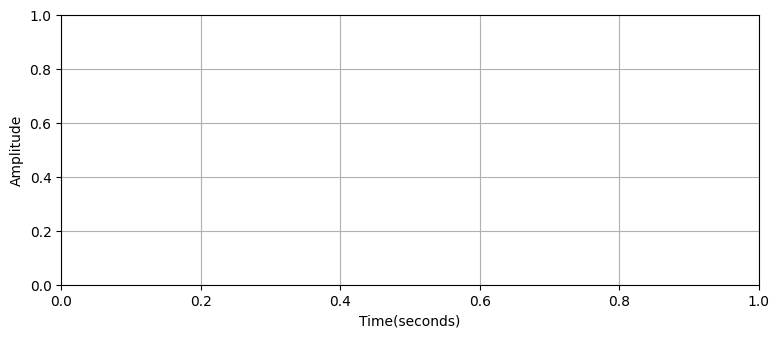

In [32]:
plt.xlabel("Time(seconds)")
plt.ylabel("Amplitude")
plt.grid(True)

In [35]:
print("Audio shape:", audio.shape)
print("Audio type:", audio.dtype)
print("Minimum value:", np.min(audio))
print("Maximum value:", np.max(audio))
print("First 20 samples:", audio[:20])

Audio shape: (265893, 2)
Audio type: int16
Minimum value: -9005
Maximum value: 10137
First 20 samples: [[ -24  -24]
 [ -28  -28]
 [ -48  -48]
 [ -67  -67]
 [ -35  -35]
 [ -64  -64]
 [ -59  -59]
 [ -84  -84]
 [-101 -101]
 [ -52  -52]
 [ -75  -75]
 [ -54  -54]
 [ -84  -84]
 [-110 -110]
 [ -77  -77]
 [-102 -102]
 [ -92  -92]
 [ -78  -78]
 [ -66  -66]
 [ -96  -96]]


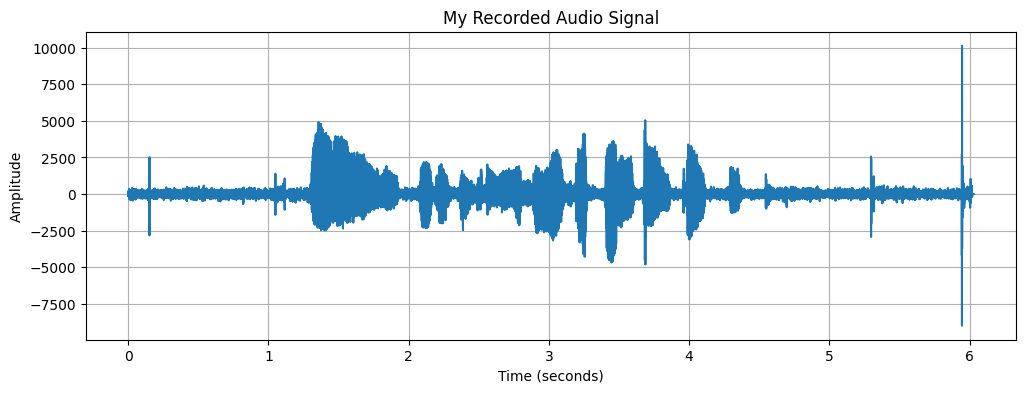

In [36]:
import numpy as np
import matplotlib.pyplot as plt

# Convert stereo audio to mono
mono_audio = audio.mean(axis=1)

time = np.arange(len(mono_audio)) / sample_rate

plt.figure(figsize=(12,4))
plt.plot(time, mono_audio)
plt.title("My Recorded Audio Signal")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.grid(True)
plt.show()

Pre-lab Question
List three devices you used today that contain DSP and for each name one signal it processes.
Answer:
1.Smartphone: Processes audio signals during phone calls and voice recording.
2.Laptop: Processes audio signals through its microphone and speakers.
3.Wi-Fi Router: Processes wireless radio signals during data transmission and reception.

ANALYSIS QUESTIONS AND ANSWERS

1. What is the sampling rate of your phone recording? How many samples are needed to store one minute of mono audio?
The sampling rate is the value obtained from the audio file. The number of samples needed for one minute is:
2. Why is a stem plot more appropriate than a continuous line for x(n)?
A stem plot is more appropriate because a discrete-time signal exists only at specific integer sample points. A continuous line may suggest values exist between those points.
3. If a = 1.1 so the exponential grows. Which system property would such a signal violate if it were an impulse response?
It would violate BIBO stability because the signal grows without bound and is not absolutely summable.


WEEK 2

SAMPLING AND QUANTIZATION

TASK 2.1 - ALIASING TABLE
Sampling rate: 10 Hz | Alias: 3.0 Hz
Sampling rate: 12 Hz | Alias: 5.0 Hz
Sampling rate: 14 Hz | Alias: 7.0 Hz
Sampling rate: 20 Hz | Alias: 7.0 Hz


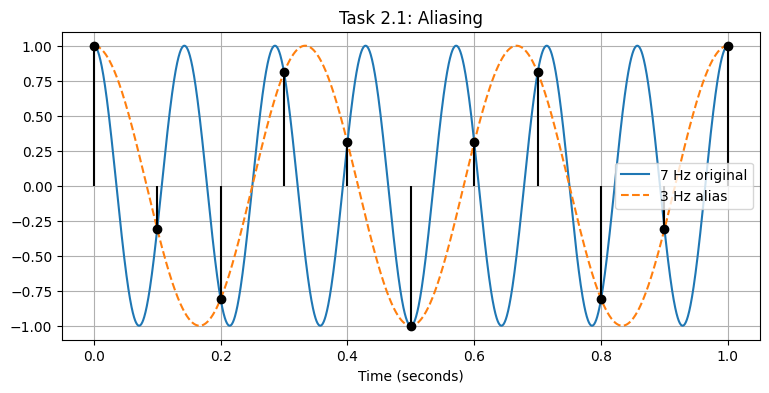


TASK 2.2 - AUDIO DOWNSAMPLING
Factor: 2 New sampling rate: 22050
Factor: 4 New sampling rate: 11025
Factor: 8 New sampling rate: 5512


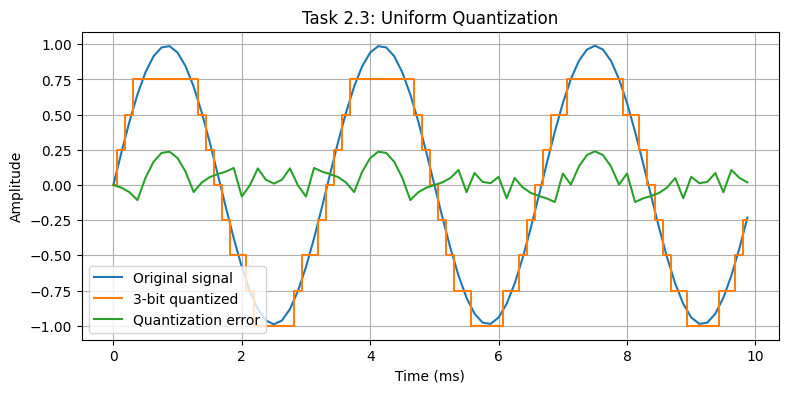

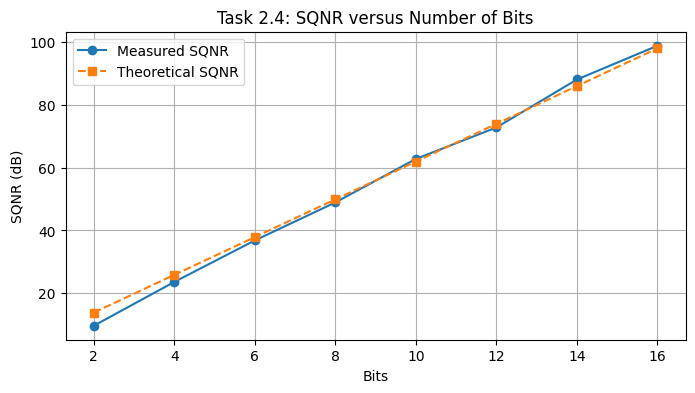


TASK 2.5 - VOICE QUANTIZATION
4 bits: SQNR = 9.05 dB
8 bits: SQNR = 30.0 dB
12 bits: SQNR = 54.08 dB

WEEK 2 TASKS COMPLETED


In [34]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
import os

# TASK 2.1: ALIASING
f0 = 7
sampling_rates = [10, 12, 14, 20]

print("TASK 2.1 - ALIASING TABLE")
for fs in sampling_rates:
    alias = abs((f0 + fs/2) % fs - fs/2)
    print("Sampling rate:", fs, "Hz | Alias:", alias, "Hz")

t = np.linspace(0, 1, 2000)
fs = 10
n = np.arange(0, fs+1)
alias = 3

plt.figure(figsize=(9,4))
plt.plot(t, np.cos(2*np.pi*7*t), label="7 Hz original")
plt.plot(t, np.cos(2*np.pi*alias*t), "--", label="3 Hz alias")
plt.stem(n/fs, np.cos(2*np.pi*7*n/fs),
         linefmt="k-", markerfmt="ko", basefmt=" ")
plt.title("Task 2.1: Aliasing")
plt.xlabel("Time (seconds)")
plt.legend()
plt.grid()
plt.show()

# TASK 2.2: AUDIO DOWNSAMPLING
if os.path.exists("my_recording.wav"):
    fs_audio, x = wavfile.read("my_recording.wav")
    x = x.mean(axis=1) if x.ndim > 1 else x.astype(float)
else:
    fs_audio = 44100
    t_audio = np.arange(0, 2, 1/fs_audio)
    x = signal.chirp(t_audio, 200, 2, 15000)

x = x.astype(float)
x = x / (np.max(np.abs(x)) + 1e-12)

print("\nTASK 2.2 - AUDIO DOWNSAMPLING")
for k in [2, 4, 8]:
    naive = x[::k]
    proper = signal.decimate(x, k, ftype="fir")
    print("Factor:", k, "New sampling rate:", fs_audio//k)

# TASK 2.3: UNIFORM QUANTIZATION
def quantize(x, bits, full_scale=1.0):
    delta = 2*full_scale / 2**bits
    q = np.round(x/delta)*delta
    return np.clip(q, -full_scale, full_scale-delta)

fs = 8000
t = np.arange(0, 0.01, 1/fs)
sine = 0.99*np.sin(2*np.pi*300*t)
xq = quantize(sine, 3)

plt.figure(figsize=(9,4))
plt.plot(t*1000, sine, label="Original signal")
plt.step(t*1000, xq, where="mid", label="3-bit quantized")
plt.plot(t*1000, sine-xq, label="Quantization error")
plt.title("Task 2.3: Uniform Quantization")
plt.xlabel("Time (ms)")
plt.ylabel("Amplitude")
plt.legend()
plt.grid()
plt.show()

# TASK 2.4: SQNR
bits = np.arange(2, 17, 2)
measured = []
theoretical = []

for B in bits:
    q = quantize(sine, B)
    error = sine-q
    measured.append(10*np.log10(np.sum(sine**2)/np.sum(error**2)))
    theoretical.append(6.02*B+1.76)

plt.figure(figsize=(8,4))
plt.plot(bits, measured, "o-", label="Measured SQNR")
plt.plot(bits, theoretical, "s--", label="Theoretical SQNR")
plt.title("Task 2.4: SQNR versus Number of Bits")
plt.xlabel("Bits")
plt.ylabel("SQNR (dB)")
plt.legend()
plt.grid()
plt.show()

# TASK 2.5: VOICE QUANTIZATION
print("\nTASK 2.5 - VOICE QUANTIZATION")
for B in [4, 8, 12]:
    q = quantize(x, B)
    error = x-q
    sqnr = 10*np.log10(np.sum(x**2)/(np.sum(error**2)+1e-12))
    print(B, "bits: SQNR =", round(sqnr, 2), "dB")

print("\nWEEK 2 TASKS COMPLETED")

WEEK 2 – PRE-LAB QUESTIONS AND ANSWERS

1. A 7 kHz signal is sampled at 10 kHz. What frequency will it appear to have?

The signal will appear at 3 kHz due to aliasing.

2. Calculate the quantization step size for an 8-bit quantizer with a range of ±1 V.

[
\Delta = \frac{2}{2^8} = 0.0078125 V
]

3. Calculate the theoretical SQNR for an 8-bit quantizer.

[
SQNR = 6.02(8)+1.76 = 49.92 dB
]

WEEK 2 – ANALYSIS QUESTIONS AND ANSWERS

1. Why does a 7 Hz signal appear as 3 Hz when sampled at 10 Hz?

Because the sampling frequency is below twice the signal frequency, aliasing occurs. Therefore, the 7 Hz signal appears as a 3 Hz signal.

2. Why can aliasing not be removed after sampling?

Aliasing cannot be removed after sampling because different original frequencies may produce the same sampled values.

3. How much does SQNR improve when one bit is added?

The SQNR improves by approximately 6.02 dB for every additional bit.

4. A temperature sensor measures temperatures from 0°C to 100°C, with a maximum change of 0.1°C per second and resolution of 0.01°C. Suggest a suitable sampling rate and number of bits.

A sampling rate of at least 10 samples per second is suitable. At least 14 bits are recommended to provide sufficient resolution over the 100°C range.

WEEK 2 – CONCLUSION

This laboratory helped demonstrate aliasing, audio downsampling, uniform quantization and signal-to-quantization-noise ratio (SQNR). The experiments showed that proper sampling and sufficient quantization bits are important for accurate digital signal representation.

WEEK 3

CONVOLUTION AND LTI SYSTEMS

TASK 3.1:Linear Convulation

Input signal x: [ 1 -1  2]
Impulse response h: [2 1 0 1]
Convolution output y: [ 2 -1  3  3 -1  2]


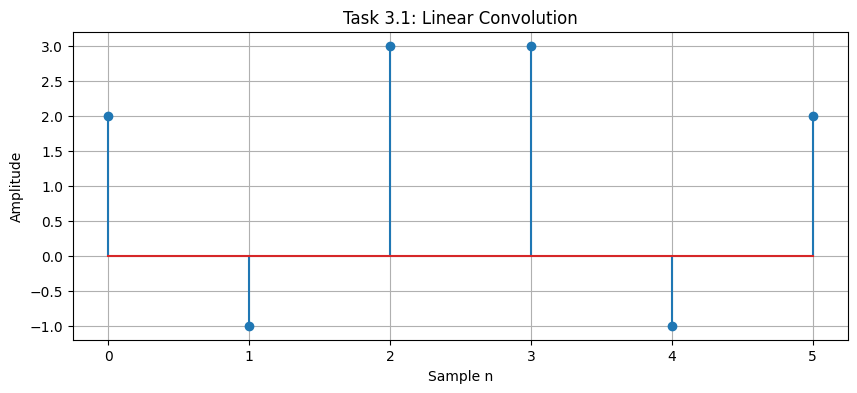

In [38]:
import numpy as np
import matplotlib.pyplot as plt

# TASK 3.1: LINEAR CONVOLUTION

x = np.array([1, -1, 2])
h = np.array([2, 1, 0, 1])

y = np.convolve(x, h)

print("Input signal x:", x)
print("Impulse response h:", h)
print("Convolution output y:", y)

plt.figure(figsize=(10, 4))

plt.stem(range(len(y)), y)
plt.title("Task 3.1: Linear Convolution")
plt.xlabel("Sample n")
plt.ylabel("Amplitude")
plt.grid()
plt.show()

TASK 3.2:Moving Average Filter

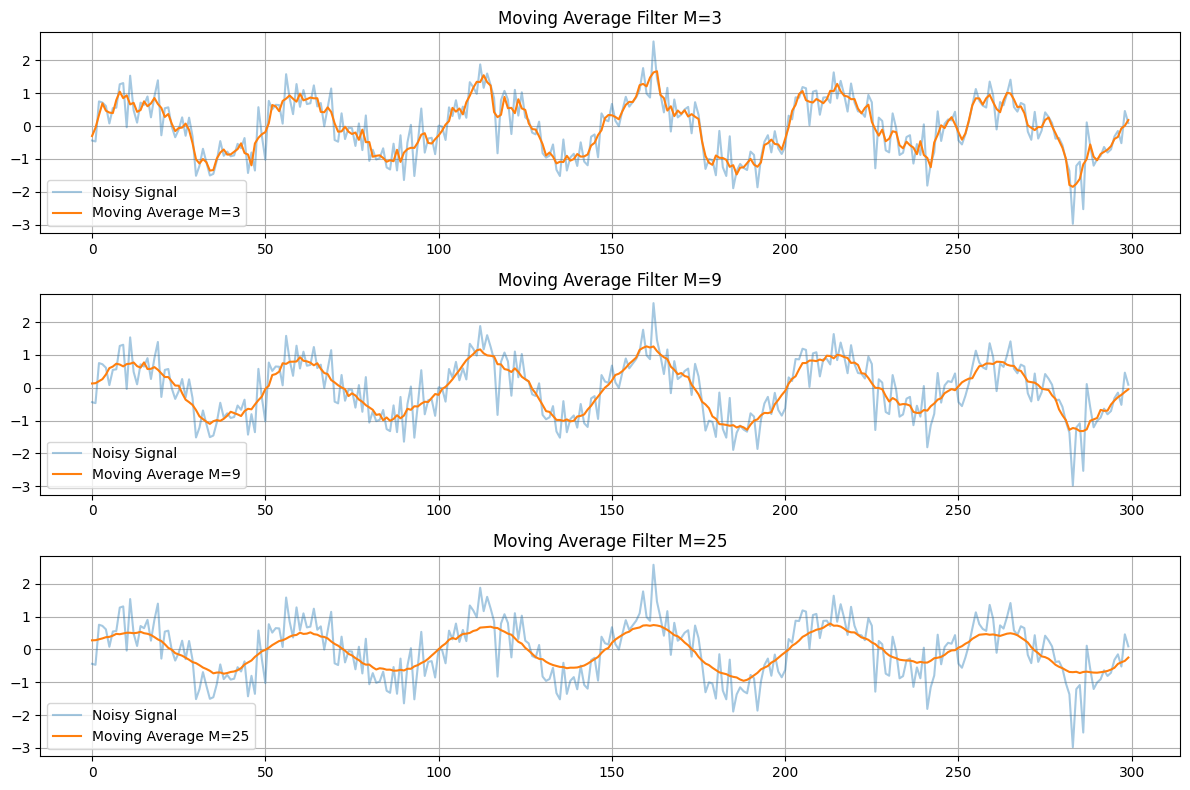

In [39]:
# TASK 3.2: MOVING AVERAGE FILTER

import numpy as np
import matplotlib.pyplot as plt

n = np.arange(300)

noise = np.random.randn(300)
x = np.sin(2*np.pi*n/50) + 0.5*noise

window_sizes = [3, 9, 25]

plt.figure(figsize=(12, 8))

for i, M in enumerate(window_sizes):
    h = np.ones(M)/M
    y = np.convolve(x, h, mode='same')

    plt.subplot(3, 1, i+1)
    plt.plot(n, x, alpha=0.4, label="Noisy Signal")
    plt.plot(n, y, label=f"Moving Average M={M}")
    plt.title(f"Moving Average Filter M={M}")
    plt.legend()
    plt.grid()

plt.tight_layout()
plt.show()

TASK 3.3:Linearity and time invariance

In [40]:
# TASK 3.3: LINEARITY AND TIME INVARIANCE

import numpy as np

n = np.arange(10)
x = np.arange(1, 11)

# System 1: y(n) = x(n)^2
y1 = x**2

# System 2: y(n) = n*x(n)
y2 = n*x

# System 3: Moving average
h = np.ones(3)/3
y3 = np.convolve(x, h, mode='full')[:len(x)]

print("System 1: x(n)^2")
print(y1)

print("\nSystem 2: n*x(n)")
print(y2)

print("\nSystem 3: Moving Average")
print(y3)

System 1: x(n)^2
[  1   4   9  16  25  36  49  64  81 100]

System 2: n*x(n)
[ 0  2  6 12 20 30 42 56 72 90]

System 3: Moving Average
[0.33333333 1.         2.         3.         4.         5.
 6.         7.         8.         9.        ]


TASK 3.4:Cross-correlation

CROSS-CORRELATION RESULTS
Noise: 1 | Estimated delay: 37 | Distance: 6345.5 m
Noise: 2 | Estimated delay: 37 | Distance: 6345.5 m
Noise: 4 | Estimated delay: 37 | Distance: 6345.5 m


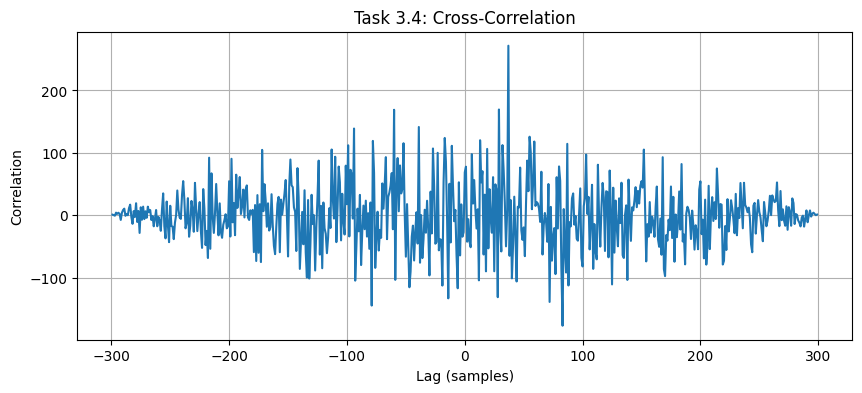

In [41]:
# TASK 3.4: CROSS-CORRELATION

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

np.random.seed(42)

delay = 37
x = np.random.randn(300)

print("CROSS-CORRELATION RESULTS")

for noise_level in [1, 2, 4]:
    noise = noise_level * np.random.randn(300)

    received = np.concatenate((np.zeros(delay), x))[:300] + noise

    corr = signal.correlate(received, x, mode="full")
    lags = signal.correlation_lags(
        len(received), len(x), mode="full"
    )

    estimated_delay = lags[np.argmax(corr)]

    distance = estimated_delay * 343 / 2

    print("Noise:", noise_level,
          "| Estimated delay:", estimated_delay,
          "| Distance:", round(distance, 2), "m")

plt.figure(figsize=(10, 4))
plt.plot(lags, corr)
plt.title("Task 3.4: Cross-Correlation")
plt.xlabel("Lag (samples)")
plt.ylabel("Correlation")
plt.grid()
plt.show()

TASK 3.5:Difference equation

Impulse Response:
[1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]

Closed-form solution:
[1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]

Final Step Response:
5.333333322157463


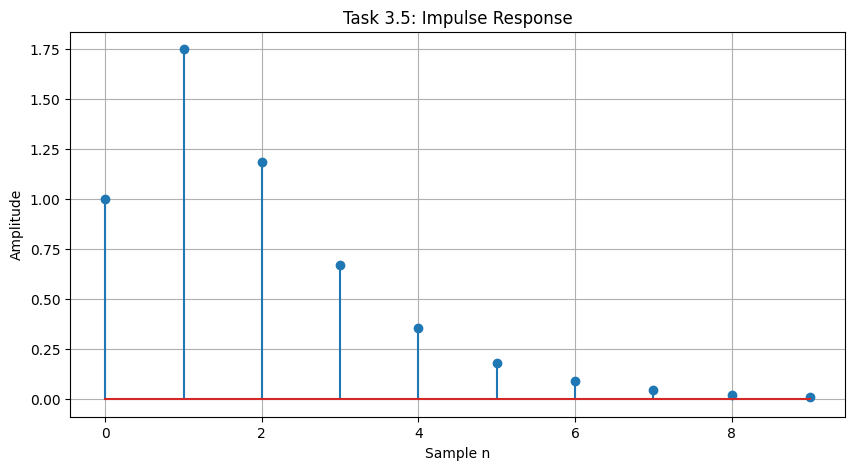

In [43]:
# TASK 3.5: DIFFERENCE EQUATION

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# Difference equation:
# y(n) - 3/4 y(n-1) + 1/8 y(n-2) = x(n) + x(n-1)

b = [1, 1]
a = [1, -0.75, 0.125]

# Impulse input
impulse = np.zeros(10)
impulse[0] = 1

# Calculate impulse response
h = signal.lfilter(b, a, impulse)

print("Impulse Response:")
print(h)

# Closed-form solution
n = np.arange(10)
h_formula = 6*(0.5**n) - 5*(0.25**n)

print("\nClosed-form solution:")
print(h_formula)

# Step response
step = np.ones(30)
step_response = signal.lfilter(b, a, step)

print("\nFinal Step Response:")
print(step_response[-1])

# Plot
plt.figure(figsize=(10, 5))
plt.stem(n, h)
plt.title("Task 3.5: Impulse Response")
plt.xlabel("Sample n")
plt.ylabel("Amplitude")
plt.grid()
plt.show()

WEEK 3 – PRE-LAB QUESTIONS AND ANSWERS

1. Find the convolution of x = [1, -1, 2] and h = [2, 1, 0, 1].

The convolution result is:

y(n) = [2, -1, 3, 3, -1, 2]

2. Is the system y(n) = n x(n) time-invariant?

No. The system is time-varying because its output depends explicitly on the time index n.

WEEK 3 – CONCLUSION

This laboratory demonstrated the principles of linear convolution, moving average filtering, linearity, time invariance and cross-correlation. The experiments also showed how difference equations can be used to determine the impulse response of a digital system. These concepts are important in understanding and analyzing Linear Time-Invariant (LTI) systems in Digital Signal Processing.

Manual convolution: [1. 3. 6. 6. 4. 1.]
NumPy convolution: [1 3 6 6 4 1]
Manual time: 3.18553495299966
NumPy time: 0.000985258999207872


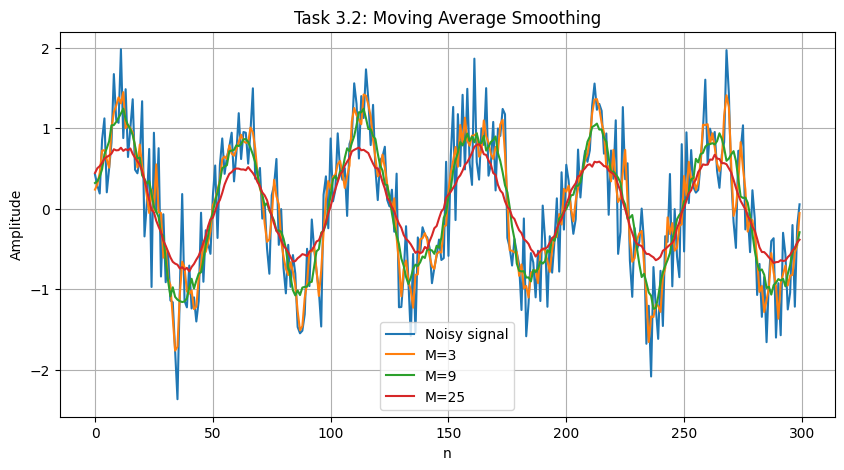


TASK 3.3
x squared Linear: False Time invariant: True
n times x Linear: True Time invariant: False
Moving average Linear: True Time invariant: True

Estimated delay: 37 samples
Distance: 12.691 metres


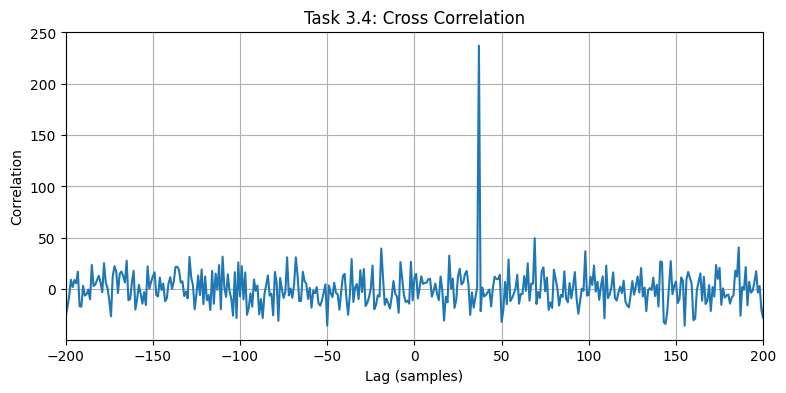


Recursive: [1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]
Lfilter: [1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]
Closed form: [1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]


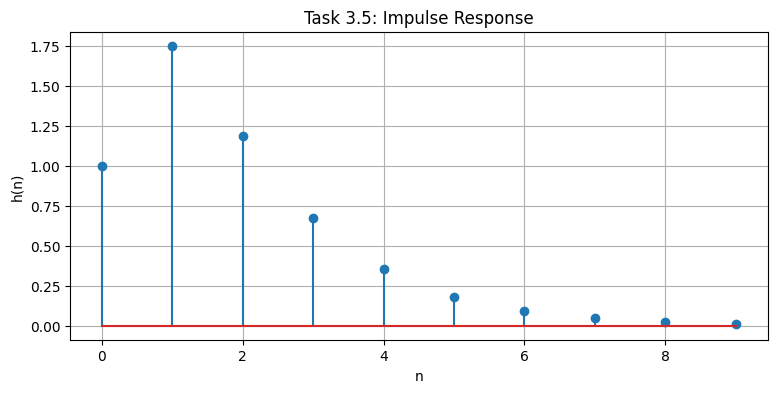

Step response final value: 5.333333322157463
H(1): 5.333333333333333

WEEK 3 TASKS COMPLETED
Manual convolution: [1. 3. 6. 6. 4. 1.]
NumPy convolution: [1 3 6 6 4 1]
Manual time: 4.779100403000484
NumPy time: 0.0014388759991561528


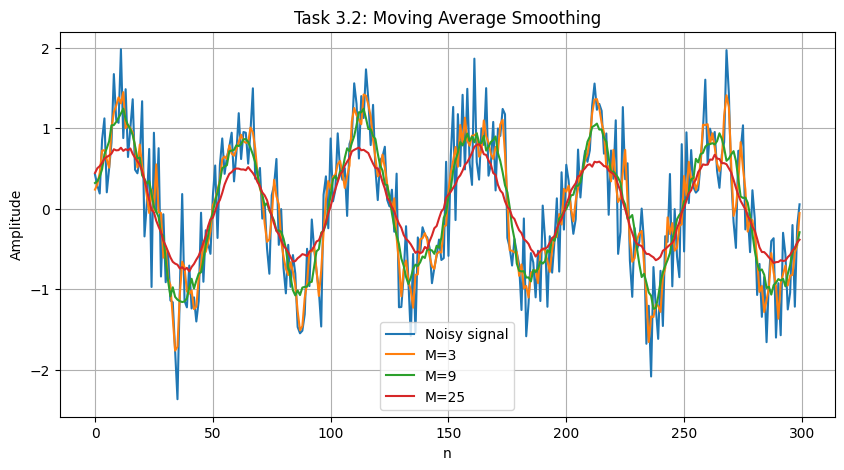


TASK 3.3
x squared Linear: False Time invariant: True
n times x Linear: True Time invariant: False
Moving average Linear: True Time invariant: True

Estimated delay: 37 samples
Distance: 12.691 metres


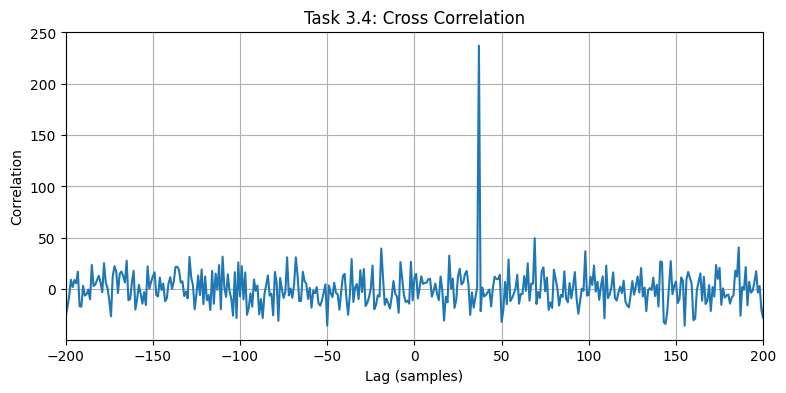


Recursive: [1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]
Lfilter: [1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]
Closed form: [1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]


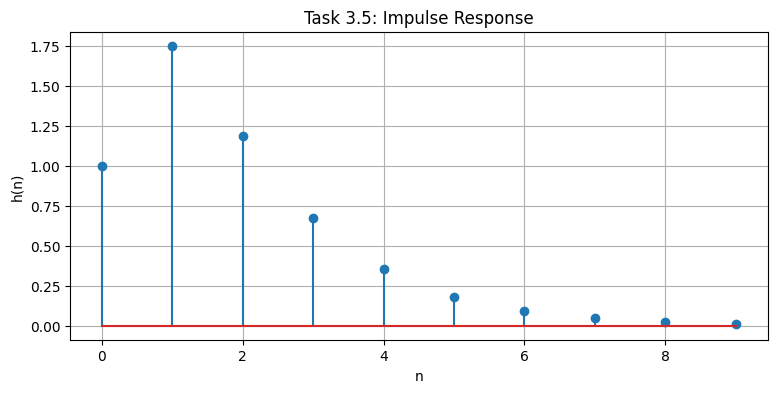

Step response final value: 5.333333322157463
H(1): 5.333333333333333

WEEK 3 TASKS COMPLETED
Manual convolution: [1. 3. 6. 6. 4. 1.]
NumPy convolution: [1 3 6 6 4 1]
Manual time: 3.1803003260010883
NumPy time: 0.0009724110004754039


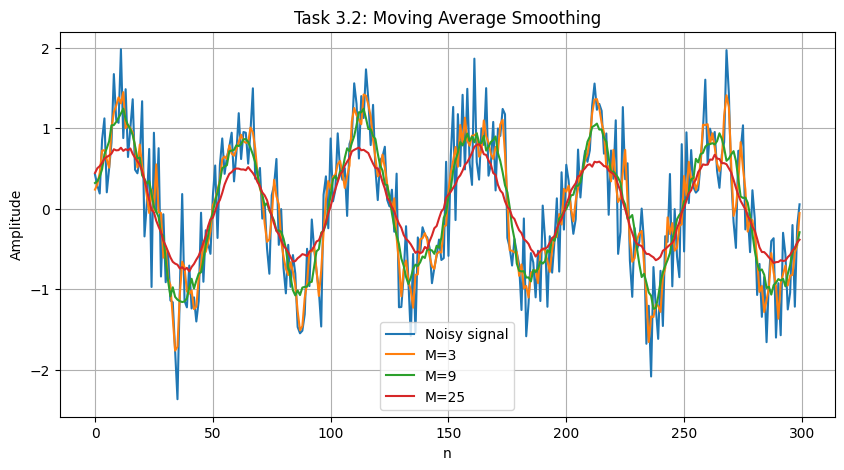


TASK 3.3
x squared Linear: False Time invariant: True
n times x Linear: True Time invariant: False
Moving average Linear: True Time invariant: True

Estimated delay: 37 samples
Distance: 12.691 metres


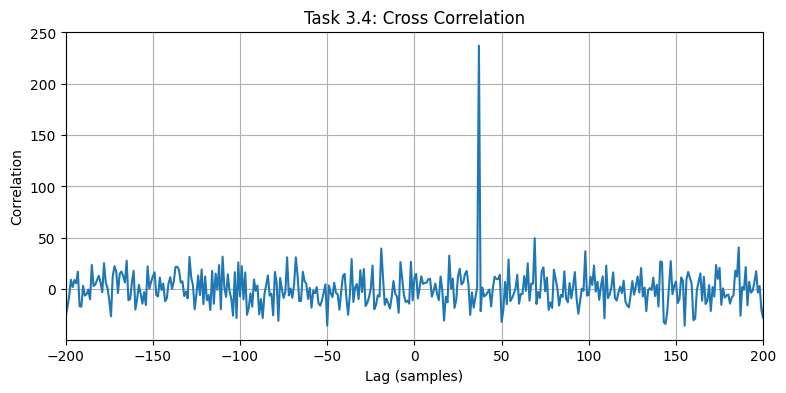


Recursive: [1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]
Lfilter: [1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]
Closed form: [1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]


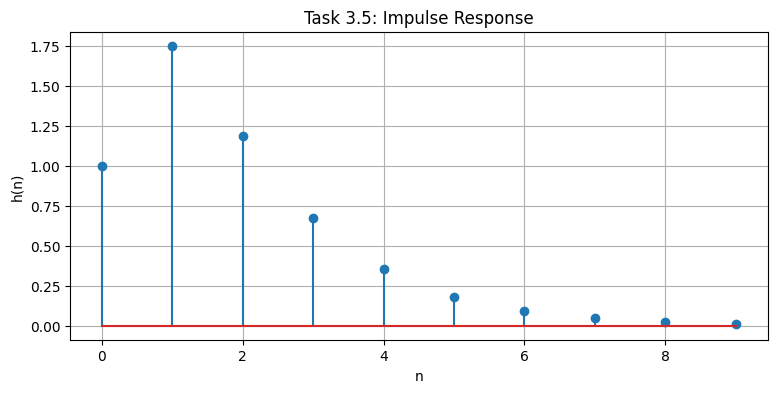

Step response final value: 5.333333322157463
H(1): 5.333333333333333

WEEK 3 TASKS COMPLETED
Manual convolution: [1. 3. 6. 6. 4. 1.]
NumPy convolution: [1 3 6 6 4 1]
Manual time: 3.1666714759994647
NumPy time: 0.001069961999746738


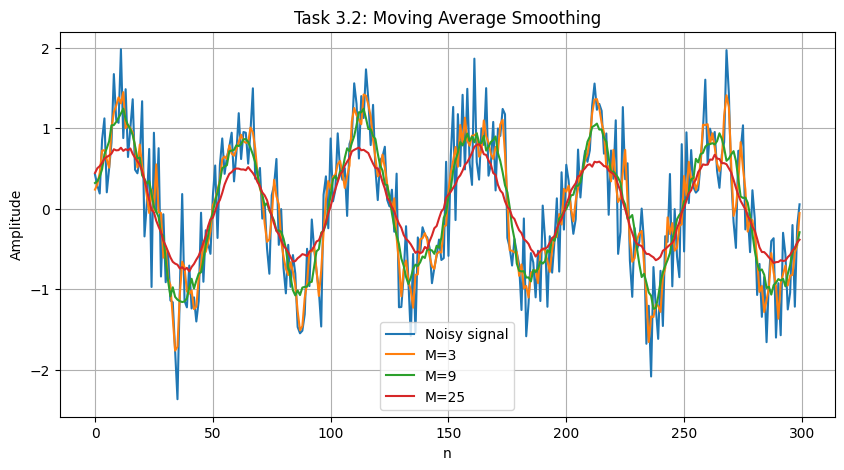


TASK 3.3
x squared Linear: False Time invariant: True
n times x Linear: True Time invariant: False
Moving average Linear: True Time invariant: True

Estimated delay: 37 samples
Distance: 12.691 metres


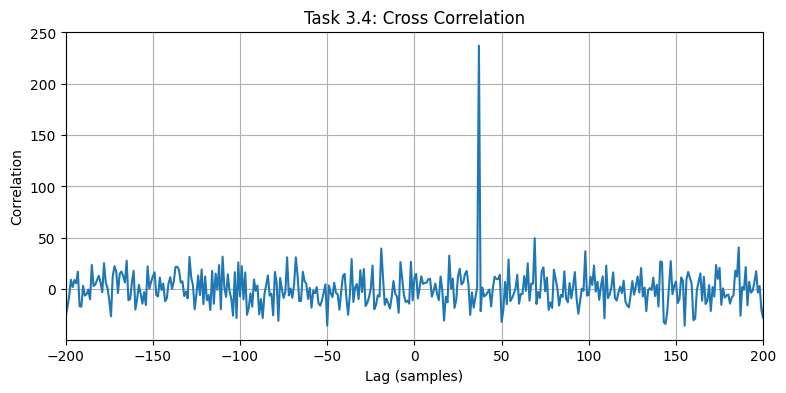


Recursive: [1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]
Lfilter: [1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]
Closed form: [1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]


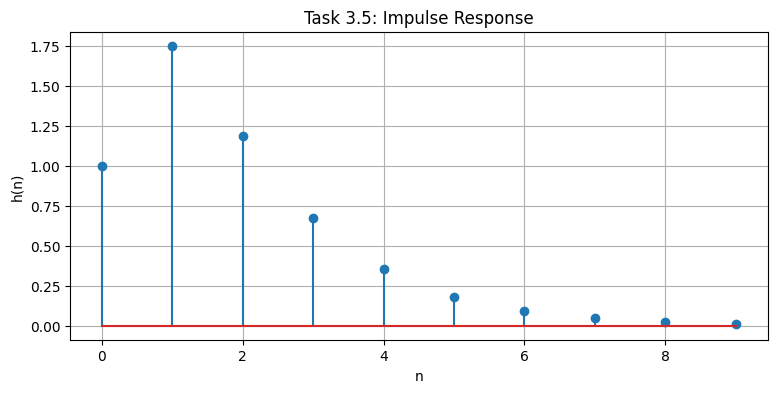

Step response final value: 5.333333322157463
H(1): 5.333333333333333

WEEK 3 TASKS COMPLETED
Manual convolution: [1. 3. 6. 6. 4. 1.]
NumPy convolution: [1 3 6 6 4 1]
Manual time: 3.917116738999539
NumPy time: 0.001447064001695253


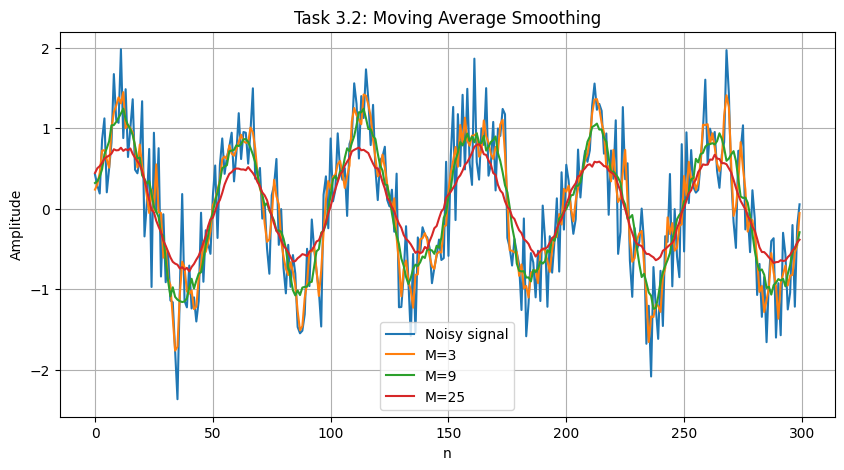


TASK 3.3
x squared Linear: False Time invariant: True
n times x Linear: True Time invariant: False
Moving average Linear: True Time invariant: True

Estimated delay: 37 samples
Distance: 12.691 metres


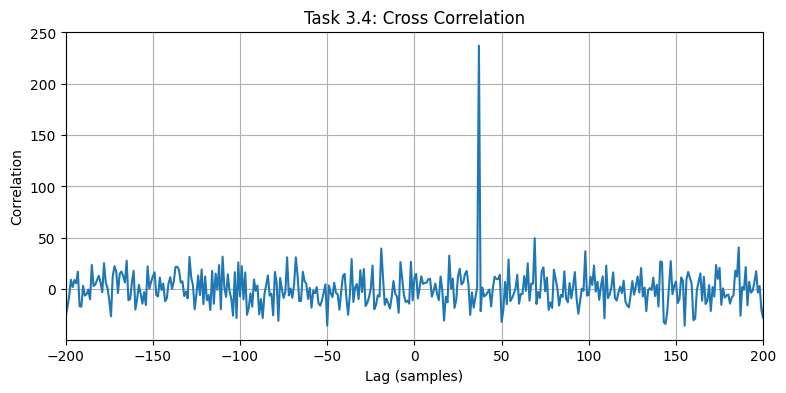


Recursive: [1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]
Lfilter: [1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]
Closed form: [1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]


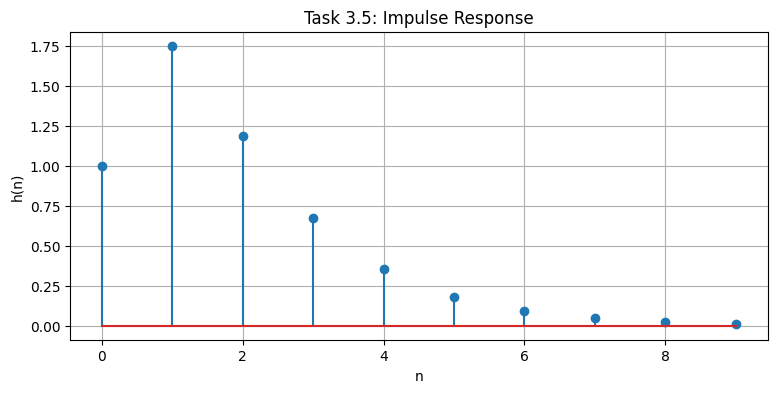

Step response final value: 5.333333322157463
H(1): 5.333333333333333

WEEK 3 TASKS COMPLETED


In [33]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
import time

# TASK 3.1: CONVOLUTION
def conv(x, h):
    N = len(x) + len(h) - 1
    y = np.zeros(N)
    for n in range(N):
        for k in range(len(x)):
            if 0 <= n-k < len(h):
                y[n] += x[k]*h[n-k]
    return y

x1 = [1, 2, 3, 1]
h1 = [1, 1, 1]

print("Manual convolution:", conv(x1,h1))
print("NumPy convolution:", np.convolve(x1,h1))

rng = np.random.default_rng(0)
a = rng.standard_normal(2000)
b = rng.standard_normal(2000)

start = time.perf_counter()
conv(a,b)
manual_time = time.perf_counter()-start

start = time.perf_counter()
np.convolve(a,b)
numpy_time = time.perf_counter()-start

print("Manual time:", manual_time)
print("NumPy time:", numpy_time)

# TASK 3.2: SMOOTHING
n = np.arange(300)
noisy = np.sin(2*np.pi*n/50) + 0.5*rng.standard_normal(300)

plt.figure(figsize=(10,5))
plt.plot(n,noisy,label="Noisy signal")

for M in [3,9,25]:
    filt = np.ones(M)/M
    smooth = np.convolve(noisy,filt,mode="same")
    plt.plot(n,smooth,label=f"M={M}")

plt.title("Task 3.2: Moving Average Smoothing")
plt.xlabel("n")
plt.ylabel("Amplitude")
plt.legend()
plt.grid()
plt.show()

# TASK 3.3: LINEARITY AND TIME INVARIANCE
x1 = rng.standard_normal(50)
x2 = rng.standard_normal(50)
a1,b1 = 2,-3

systems = {
    "x squared": lambda x: x**2,
    "n times x": lambda x: np.arange(len(x))*x,
    "Moving average": lambda x: np.convolve(x,np.ones(3)/3)[:len(x)]
}

print("\nTASK 3.3")
for name,T in systems.items():
    linear = np.allclose(T(a1*x1+b1*x2),
                         a1*T(x1)+b1*T(x2))
    xd = np.concatenate([np.zeros(5),x1])[:50]
    yd = np.concatenate([np.zeros(5),T(x1)])[:50]
    tinv = np.allclose(T(xd),yd)
    print(name, "Linear:",linear,
          "Time invariant:",tinv)

# TASK 3.4: CROSS CORRELATION
fs = 1000
x = rng.standard_normal(500)
delay = 37
y = np.concatenate([np.zeros(delay),0.6*x])[:500]
y += 0.5*rng.standard_normal(500)

r = signal.correlate(y,x,mode="full")
lags = signal.correlation_lags(len(y),len(x),mode="full")
estimated = lags[np.argmax(r)]

print("\nEstimated delay:",estimated,"samples")
print("Distance:",round(estimated/fs*343,3),"metres")

plt.figure(figsize=(9,4))
plt.plot(lags,r)
plt.xlim(-200,200)
plt.title("Task 3.4: Cross Correlation")
plt.xlabel("Lag (samples)")
plt.ylabel("Correlation")
plt.grid()
plt.show()

# TASK 3.5: DIFFERENCE EQUATION
impulse = np.zeros(10)
impulse[0] = 1

h_recursive = np.zeros(10)
for i in range(10):
    x_now = impulse[i]
    x_prev = impulse[i-1] if i>=1 else 0
    y_prev = h_recursive[i-1] if i>=1 else 0
    y_prev2 = h_recursive[i-2] if i>=2 else 0
    h_recursive[i] = x_now+x_prev+0.75*y_prev-0.125*y_prev2

h_filter = signal.lfilter([1,1],[1,-0.75,0.125],impulse)
h_closed = 6*(0.5**np.arange(10))-5*(0.25**np.arange(10))

print("\nRecursive:",h_recursive)
print("Lfilter:",h_filter)
print("Closed form:",h_closed)

plt.figure(figsize=(9,4))
plt.stem(np.arange(10),h_recursive)
plt.title("Task 3.5: Impulse Response")
plt.xlabel("n")
plt.ylabel("h(n)")
plt.grid()
plt.show()

step_input = np.ones(30)
step_response = signal.lfilter([1,1],[1,-0.75,0.125],step_input)
print("Step response final value:",step_response[-1])
print("H(1):",2/(1-0.75+0.125))

print("\nWEEK 3 TASKS COMPLETED")

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
import time

# TASK 3.1: CONVOLUTION
def conv(x, h):
    N = len(x) + len(h) - 1
    y = np.zeros(N)
    for n in range(N):
        for k in range(len(x)):
            if 0 <= n-k < len(h):
                y[n] += x[k]*h[n-k]
    return y

x1 = [1, 2, 3, 1]
h1 = [1, 1, 1]

print("Manual convolution:", conv(x1,h1))
print("NumPy convolution:", np.convolve(x1,h1))

rng = np.random.default_rng(0)
a = rng.standard_normal(2000)
b = rng.standard_normal(2000)

start = time.perf_counter()
conv(a,b)
manual_time = time.perf_counter()-start

start = time.perf_counter()
np.convolve(a,b)
numpy_time = time.perf_counter()-start

print("Manual time:", manual_time)
print("NumPy time:", numpy_time)

# TASK 3.2: SMOOTHING
n = np.arange(300)
noisy = np.sin(2*np.pi*n/50) + 0.5*rng.standard_normal(300)

plt.figure(figsize=(10,5))
plt.plot(n,noisy,label="Noisy signal")

for M in [3,9,25]:
    filt = np.ones(M)/M
    smooth = np.convolve(noisy,filt,mode="same")
    plt.plot(n,smooth,label=f"M={M}")

plt.title("Task 3.2: Moving Average Smoothing")
plt.xlabel("n")
plt.ylabel("Amplitude")
plt.legend()
plt.grid()
plt.show()

# TASK 3.3: LINEARITY AND TIME INVARIANCE
x1 = rng.standard_normal(50)
x2 = rng.standard_normal(50)
a1,b1 = 2,-3

systems = {
    "x squared": lambda x: x**2,
    "n times x": lambda x: np.arange(len(x))*x,
    "Moving average": lambda x: np.convolve(x,np.ones(3)/3)[:len(x)]
}

print("\nTASK 3.3")
for name,T in systems.items():
    linear = np.allclose(T(a1*x1+b1*x2),
                         a1*T(x1)+b1*T(x2))
    xd = np.concatenate([np.zeros(5),x1])[:50]
    yd = np.concatenate([np.zeros(5),T(x1)])[:50]
    tinv = np.allclose(T(xd),yd)
    print(name, "Linear:",linear,
          "Time invariant:",tinv)

# TASK 3.4: CROSS CORRELATION
fs = 1000
x = rng.standard_normal(500)
delay = 37
y = np.concatenate([np.zeros(delay),0.6*x])[:500]
y += 0.5*rng.standard_normal(500)

r = signal.correlate(y,x,mode="full")
lags = signal.correlation_lags(len(y),len(x),mode="full")
estimated = lags[np.argmax(r)]

print("\nEstimated delay:",estimated,"samples")
print("Distance:",round(estimated/fs*343,3),"metres")

plt.figure(figsize=(9,4))
plt.plot(lags,r)
plt.xlim(-200,200)
plt.title("Task 3.4: Cross Correlation")
plt.xlabel("Lag (samples)")
plt.ylabel("Correlation")
plt.grid()
plt.show()

# TASK 3.5: DIFFERENCE EQUATION
impulse = np.zeros(10)
impulse[0] = 1

h_recursive = np.zeros(10)
for i in range(10):
    x_now = impulse[i]
    x_prev = impulse[i-1] if i>=1 else 0
    y_prev = h_recursive[i-1] if i>=1 else 0
    y_prev2 = h_recursive[i-2] if i>=2 else 0
    h_recursive[i] = x_now+x_prev+0.75*y_prev-0.125*y_prev2

h_filter = signal.lfilter([1,1],[1,-0.75,0.125],impulse)
h_closed = 6*(0.5**np.arange(10))-5*(0.25**np.arange(10))

print("\nRecursive:",h_recursive)
print("Lfilter:",h_filter)
print("Closed form:",h_closed)

plt.figure(figsize=(9,4))
plt.stem(np.arange(10),h_recursive)
plt.title("Task 3.5: Impulse Response")
plt.xlabel("n")
plt.ylabel("h(n)")
plt.grid()
plt.show()

step_input = np.ones(30)
step_response = signal.lfilter([1,1],[1,-0.75,0.125],step_input)
print("Step response final value:",step_response[-1])
print("H(1):",2/(1-0.75+0.125))

print("\nWEEK 3 TASKS COMPLETED")

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
import time

# TASK 3.1: CONVOLUTION
def conv(x, h):
    N = len(x) + len(h) - 1
    y = np.zeros(N)
    for n in range(N):
        for k in range(len(x)):
            if 0 <= n-k < len(h):
                y[n] += x[k]*h[n-k]
    return y

x1 = [1, 2, 3, 1]
h1 = [1, 1, 1]

print("Manual convolution:", conv(x1,h1))
print("NumPy convolution:", np.convolve(x1,h1))

rng = np.random.default_rng(0)
a = rng.standard_normal(2000)
b = rng.standard_normal(2000)

start = time.perf_counter()
conv(a,b)
manual_time = time.perf_counter()-start

start = time.perf_counter()
np.convolve(a,b)
numpy_time = time.perf_counter()-start

print("Manual time:", manual_time)
print("NumPy time:", numpy_time)

# TASK 3.2: SMOOTHING
n = np.arange(300)
noisy = np.sin(2*np.pi*n/50) + 0.5*rng.standard_normal(300)

plt.figure(figsize=(10,5))
plt.plot(n,noisy,label="Noisy signal")

for M in [3,9,25]:
    filt = np.ones(M)/M
    smooth = np.convolve(noisy,filt,mode="same")
    plt.plot(n,smooth,label=f"M={M}")

plt.title("Task 3.2: Moving Average Smoothing")
plt.xlabel("n")
plt.ylabel("Amplitude")
plt.legend()
plt.grid()
plt.show()

# TASK 3.3: LINEARITY AND TIME INVARIANCE
x1 = rng.standard_normal(50)
x2 = rng.standard_normal(50)
a1,b1 = 2,-3

systems = {
    "x squared": lambda x: x**2,
    "n times x": lambda x: np.arange(len(x))*x,
    "Moving average": lambda x: np.convolve(x,np.ones(3)/3)[:len(x)]
}

print("\nTASK 3.3")
for name,T in systems.items():
    linear = np.allclose(T(a1*x1+b1*x2),
                         a1*T(x1)+b1*T(x2))
    xd = np.concatenate([np.zeros(5),x1])[:50]
    yd = np.concatenate([np.zeros(5),T(x1)])[:50]
    tinv = np.allclose(T(xd),yd)
    print(name, "Linear:",linear,
          "Time invariant:",tinv)

# TASK 3.4: CROSS CORRELATION
fs = 1000
x = rng.standard_normal(500)
delay = 37
y = np.concatenate([np.zeros(delay),0.6*x])[:500]
y += 0.5*rng.standard_normal(500)

r = signal.correlate(y,x,mode="full")
lags = signal.correlation_lags(len(y),len(x),mode="full")
estimated = lags[np.argmax(r)]

print("\nEstimated delay:",estimated,"samples")
print("Distance:",round(estimated/fs*343,3),"metres")

plt.figure(figsize=(9,4))
plt.plot(lags,r)
plt.xlim(-200,200)
plt.title("Task 3.4: Cross Correlation")
plt.xlabel("Lag (samples)")
plt.ylabel("Correlation")
plt.grid()
plt.show()

# TASK 3.5: DIFFERENCE EQUATION
impulse = np.zeros(10)
impulse[0] = 1

h_recursive = np.zeros(10)
for i in range(10):
    x_now = impulse[i]
    x_prev = impulse[i-1] if i>=1 else 0
    y_prev = h_recursive[i-1] if i>=1 else 0
    y_prev2 = h_recursive[i-2] if i>=2 else 0
    h_recursive[i] = x_now+x_prev+0.75*y_prev-0.125*y_prev2

h_filter = signal.lfilter([1,1],[1,-0.75,0.125],impulse)
h_closed = 6*(0.5**np.arange(10))-5*(0.25**np.arange(10))

print("\nRecursive:",h_recursive)
print("Lfilter:",h_filter)
print("Closed form:",h_closed)

plt.figure(figsize=(9,4))
plt.stem(np.arange(10),h_recursive)
plt.title("Task 3.5: Impulse Response")
plt.xlabel("n")
plt.ylabel("h(n)")
plt.grid()
plt.show()

step_input = np.ones(30)
step_response = signal.lfilter([1,1],[1,-0.75,0.125],step_input)
print("Step response final value:",step_response[-1])
print("H(1):",2/(1-0.75+0.125))

print("\nWEEK 3 TASKS COMPLETED")

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
import time

# TASK 3.1: CONVOLUTION
def conv(x, h):
    N = len(x) + len(h) - 1
    y = np.zeros(N)
    for n in range(N):
        for k in range(len(x)):
            if 0 <= n-k < len(h):
                y[n] += x[k]*h[n-k]
    return y

x1 = [1, 2, 3, 1]
h1 = [1, 1, 1]

print("Manual convolution:", conv(x1,h1))
print("NumPy convolution:", np.convolve(x1,h1))

rng = np.random.default_rng(0)
a = rng.standard_normal(2000)
b = rng.standard_normal(2000)

start = time.perf_counter()
conv(a,b)
manual_time = time.perf_counter()-start

start = time.perf_counter()
np.convolve(a,b)
numpy_time = time.perf_counter()-start

print("Manual time:", manual_time)
print("NumPy time:", numpy_time)

# TASK 3.2: SMOOTHING
n = np.arange(300)
noisy = np.sin(2*np.pi*n/50) + 0.5*rng.standard_normal(300)

plt.figure(figsize=(10,5))
plt.plot(n,noisy,label="Noisy signal")

for M in [3,9,25]:
    filt = np.ones(M)/M
    smooth = np.convolve(noisy,filt,mode="same")
    plt.plot(n,smooth,label=f"M={M}")

plt.title("Task 3.2: Moving Average Smoothing")
plt.xlabel("n")
plt.ylabel("Amplitude")
plt.legend()
plt.grid()
plt.show()

# TASK 3.3: LINEARITY AND TIME INVARIANCE
x1 = rng.standard_normal(50)
x2 = rng.standard_normal(50)
a1,b1 = 2,-3

systems = {
    "x squared": lambda x: x**2,
    "n times x": lambda x: np.arange(len(x))*x,
    "Moving average": lambda x: np.convolve(x,np.ones(3)/3)[:len(x)]
}

print("\nTASK 3.3")
for name,T in systems.items():
    linear = np.allclose(T(a1*x1+b1*x2),
                         a1*T(x1)+b1*T(x2))
    xd = np.concatenate([np.zeros(5),x1])[:50]
    yd = np.concatenate([np.zeros(5),T(x1)])[:50]
    tinv = np.allclose(T(xd),yd)
    print(name, "Linear:",linear,
          "Time invariant:",tinv)

# TASK 3.4: CROSS CORRELATION
fs = 1000
x = rng.standard_normal(500)
delay = 37
y = np.concatenate([np.zeros(delay),0.6*x])[:500]
y += 0.5*rng.standard_normal(500)

r = signal.correlate(y,x,mode="full")
lags = signal.correlation_lags(len(y),len(x),mode="full")
estimated = lags[np.argmax(r)]

print("\nEstimated delay:",estimated,"samples")
print("Distance:",round(estimated/fs*343,3),"metres")

plt.figure(figsize=(9,4))
plt.plot(lags,r)
plt.xlim(-200,200)
plt.title("Task 3.4: Cross Correlation")
plt.xlabel("Lag (samples)")
plt.ylabel("Correlation")
plt.grid()
plt.show()

# TASK 3.5: DIFFERENCE EQUATION
impulse = np.zeros(10)
impulse[0] = 1

h_recursive = np.zeros(10)
for i in range(10):
    x_now = impulse[i]
    x_prev = impulse[i-1] if i>=1 else 0
    y_prev = h_recursive[i-1] if i>=1 else 0
    y_prev2 = h_recursive[i-2] if i>=2 else 0
    h_recursive[i] = x_now+x_prev+0.75*y_prev-0.125*y_prev2

h_filter = signal.lfilter([1,1],[1,-0.75,0.125],impulse)
h_closed = 6*(0.5**np.arange(10))-5*(0.25**np.arange(10))

print("\nRecursive:",h_recursive)
print("Lfilter:",h_filter)
print("Closed form:",h_closed)

plt.figure(figsize=(9,4))
plt.stem(np.arange(10),h_recursive)
plt.title("Task 3.5: Impulse Response")
plt.xlabel("n")
plt.ylabel("h(n)")
plt.grid()
plt.show()

step_input = np.ones(30)
step_response = signal.lfilter([1,1],[1,-0.75,0.125],step_input)
print("Step response final value:",step_response[-1])
print("H(1):",2/(1-0.75+0.125))

print("\nWEEK 3 TASKS COMPLETED")

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
import time

# TASK 3.1: CONVOLUTION
def conv(x, h):
    N = len(x) + len(h) - 1
    y = np.zeros(N)
    for n in range(N):
        for k in range(len(x)):
            if 0 <= n-k < len(h):
                y[n] += x[k]*h[n-k]
    return y

x1 = [1, 2, 3, 1]
h1 = [1, 1, 1]

print("Manual convolution:", conv(x1,h1))
print("NumPy convolution:", np.convolve(x1,h1))

rng = np.random.default_rng(0)
a = rng.standard_normal(2000)
b = rng.standard_normal(2000)

start = time.perf_counter()
conv(a,b)
manual_time = time.perf_counter()-start

start = time.perf_counter()
np.convolve(a,b)
numpy_time = time.perf_counter()-start

print("Manual time:", manual_time)
print("NumPy time:", numpy_time)

# TASK 3.2: SMOOTHING
n = np.arange(300)
noisy = np.sin(2*np.pi*n/50) + 0.5*rng.standard_normal(300)

plt.figure(figsize=(10,5))
plt.plot(n,noisy,label="Noisy signal")

for M in [3,9,25]:
    filt = np.ones(M)/M
    smooth = np.convolve(noisy,filt,mode="same")
    plt.plot(n,smooth,label=f"M={M}")

plt.title("Task 3.2: Moving Average Smoothing")
plt.xlabel("n")
plt.ylabel("Amplitude")
plt.legend()
plt.grid()
plt.show()

# TASK 3.3: LINEARITY AND TIME INVARIANCE
x1 = rng.standard_normal(50)
x2 = rng.standard_normal(50)
a1,b1 = 2,-3

systems = {
    "x squared": lambda x: x**2,
    "n times x": lambda x: np.arange(len(x))*x,
    "Moving average": lambda x: np.convolve(x,np.ones(3)/3)[:len(x)]
}

print("\nTASK 3.3")
for name,T in systems.items():
    linear = np.allclose(T(a1*x1+b1*x2),
                         a1*T(x1)+b1*T(x2))
    xd = np.concatenate([np.zeros(5),x1])[:50]
    yd = np.concatenate([np.zeros(5),T(x1)])[:50]
    tinv = np.allclose(T(xd),yd)
    print(name, "Linear:",linear,
          "Time invariant:",tinv)

# TASK 3.4: CROSS CORRELATION
fs = 1000
x = rng.standard_normal(500)
delay = 37
y = np.concatenate([np.zeros(delay),0.6*x])[:500]
y += 0.5*rng.standard_normal(500)

r = signal.correlate(y,x,mode="full")
lags = signal.correlation_lags(len(y),len(x),mode="full")
estimated = lags[np.argmax(r)]

print("\nEstimated delay:",estimated,"samples")
print("Distance:",round(estimated/fs*343,3),"metres")

plt.figure(figsize=(9,4))
plt.plot(lags,r)
plt.xlim(-200,200)
plt.title("Task 3.4: Cross Correlation")
plt.xlabel("Lag (samples)")
plt.ylabel("Correlation")
plt.grid()
plt.show()

# TASK 3.5: DIFFERENCE EQUATION
impulse = np.zeros(10)
impulse[0] = 1

h_recursive = np.zeros(10)
for i in range(10):
    x_now = impulse[i]
    x_prev = impulse[i-1] if i>=1 else 0
    y_prev = h_recursive[i-1] if i>=1 else 0
    y_prev2 = h_recursive[i-2] if i>=2 else 0
    h_recursive[i] = x_now+x_prev+0.75*y_prev-0.125*y_prev2

h_filter = signal.lfilter([1,1],[1,-0.75,0.125],impulse)
h_closed = 6*(0.5**np.arange(10))-5*(0.25**np.arange(10))

print("\nRecursive:",h_recursive)
print("Lfilter:",h_filter)
print("Closed form:",h_closed)

plt.figure(figsize=(9,4))
plt.stem(np.arange(10),h_recursive)
plt.title("Task 3.5: Impulse Response")
plt.xlabel("n")
plt.ylabel("h(n)")
plt.grid()
plt.show()

step_input = np.ones(30)
step_response = signal.lfilter([1,1],[1,-0.75,0.125],step_input)
print("Step response final value:",step_response[-1])
print("H(1):",2/(1-0.75+0.125))

print("\nWEEK 3 TASKS COMPLETED")

**WEEK** **4**

Z-TRANSFORM,POLES AND ZEROS

TASK 4.1:Pole-zero plot and frequency response

Zeros: [-1.]
Poles: [0.5  0.25]


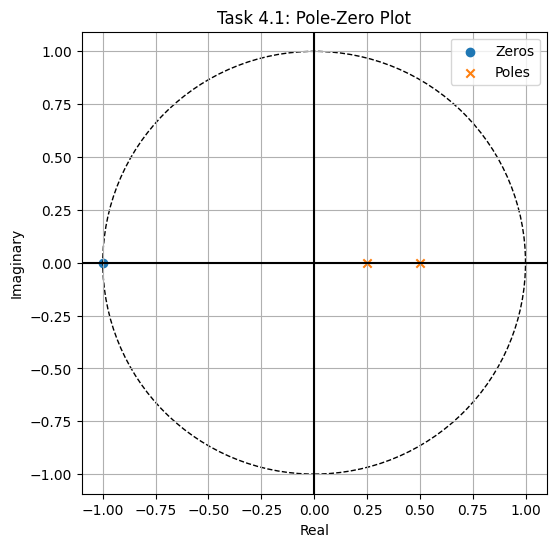

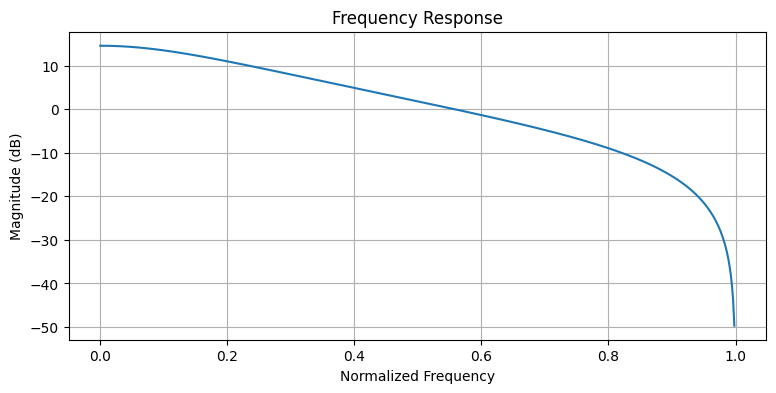

In [44]:
# TASK 4.1: POLE-ZERO PLOT AND FREQUENCY RESPONSE

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

b = [1, 1]
a = [1, -0.75, 0.125]

# Find zeros and poles
zeros = np.roots(b)
poles = np.roots(a)

print("Zeros:", zeros)
print("Poles:", poles)

# Pole-zero plot
plt.figure(figsize=(6, 6))

plt.scatter(np.real(zeros), np.imag(zeros),
            marker='o', label='Zeros')
plt.scatter(np.real(poles), np.imag(poles),
            marker='x', label='Poles')

circle = plt.Circle((0, 0), 1, fill=False, linestyle='--')
plt.gca().add_patch(circle)

plt.axhline(0, color='black')
plt.axvline(0, color='black')
plt.xlabel("Real")
plt.ylabel("Imaginary")
plt.title("Task 4.1: Pole-Zero Plot")
plt.legend()
plt.grid()
plt.axis('equal')
plt.show()

# Frequency response
w, h = signal.freqz(b, a)

plt.figure(figsize=(9, 4))
plt.plot(w/np.pi, 20*np.log10(np.abs(h) + 1e-12))
plt.title("Frequency Response")
plt.xlabel("Normalized Frequency")
plt.ylabel("Magnitude (dB)")
plt.grid()
plt.show()

TASK 4.2:Inverse Z-Transform

Residues: [-5.  6.]
Poles: [0.25 0.5 ]
Direct terms: []

Impulse response:
[1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]

Closed-form solution:
[1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]


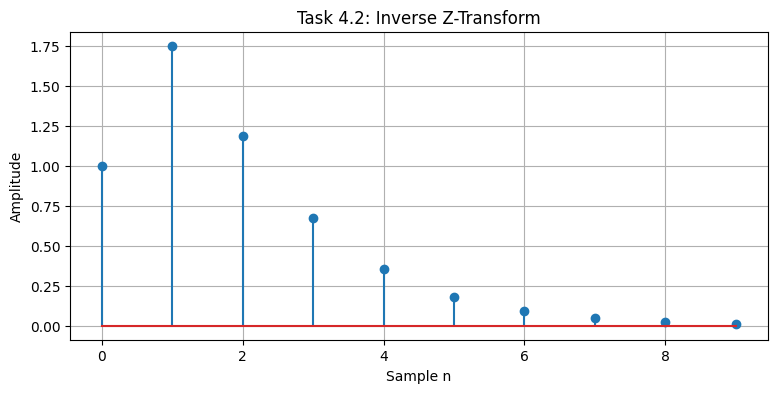

In [45]:
# TASK 4.2: INVERSE Z-TRANSFORM

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

b = [1, 1]
a = [1, -0.75, 0.125]

# Partial fraction expansion
r, p, k = signal.residuez(b, a)

print("Residues:", r)
print("Poles:", p)
print("Direct terms:", k)

# Impulse response using lfilter
impulse = np.zeros(10)
impulse[0] = 1

h = signal.lfilter(b, a, impulse)

# Closed-form solution
n = np.arange(10)
h_formula = 6*(0.5**n) - 5*(0.25**n)

print("\nImpulse response:")
print(h)

print("\nClosed-form solution:")
print(h_formula)

# Plot
plt.figure(figsize=(9, 4))
plt.stem(n, h)
plt.title("Task 4.2: Inverse Z-Transform")
plt.xlabel("Sample n")
plt.ylabel("Amplitude")
plt.grid()
plt.show()

TASK 4.3:Effect of pole radius on system response

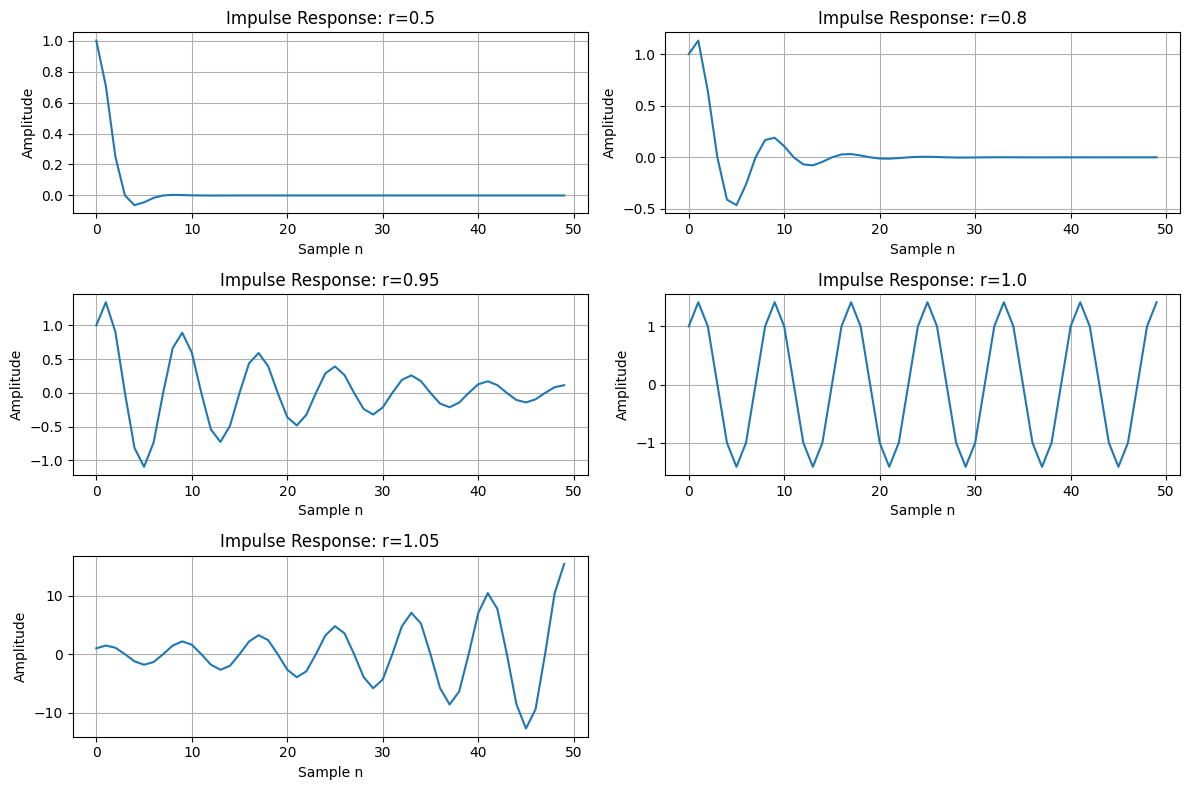

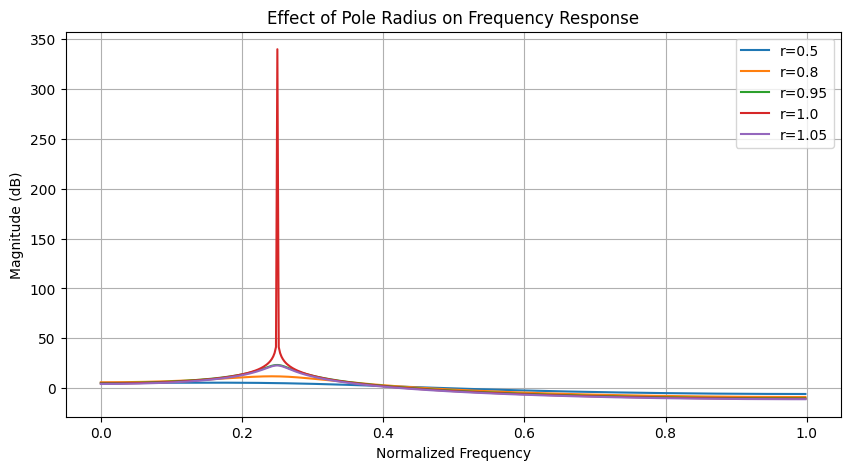

In [46]:
# TASK 4.3: EFFECT OF POLE RADIUS

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

radii = [0.5, 0.8, 0.95, 1.0, 1.05]
theta = np.pi/4

n = np.arange(50)

plt.figure(figsize=(12, 8))

for i, r in enumerate(radii):
    a = [1, -2*r*np.cos(theta), r**2]
    b = [1]

    impulse = np.zeros(50)
    impulse[0] = 1

    h = signal.lfilter(b, a, impulse)

    plt.subplot(3, 2, i+1)
    plt.plot(n, h)
    plt.title(f"Impulse Response: r={r}")
    plt.xlabel("Sample n")
    plt.ylabel("Amplitude")
    plt.grid()

plt.tight_layout()
plt.show()

# Frequency response comparison
plt.figure(figsize=(10, 5))

for r in radii:
    a = [1, -2*r*np.cos(theta), r**2]
    w, response = signal.freqz([1], a)

    magnitude = 20*np.log10(np.abs(response) + 1e-12)

    plt.plot(w/np.pi, magnitude, label=f"r={r}")

plt.title("Effect of Pole Radius on Frequency Response")
plt.xlabel("Normalized Frequency")
plt.ylabel("Magnitude (dB)")
plt.legend()
plt.grid()
plt.show()

TASK 4.4:CLASSIFICATION OF DIGITAL SYSTEMS

In [47]:
# TASK 4.4: CLASSIFICATION OF DIGITAL SYSTEMS

import numpy as np

systems = {
    "H1": ([1], [1, -1.6, 0.89]),
    "H2": ([1, 1], [1, -2.5, 1]),
    "H3": ([1], [1, 0.5, -0.5]),
    "H4": ([1, 0, 0, 0, -1], [1])
}

print("SYSTEM CLASSIFICATION")

for name, (b, a) in systems.items():
    poles = np.roots(a)

    stable = np.all(np.abs(poles) < 1)

    print("\n", name)
    print("Poles:", poles)
    print("Pole Magnitudes:", np.abs(poles))

    if stable:
        print("System is STABLE")
    else:
        print("System is NOT BIBO STABLE")

SYSTEM CLASSIFICATION

 H1
Poles: [0.8+0.5j 0.8-0.5j]
Pole Magnitudes: [0.94339811 0.94339811]
System is STABLE

 H2
Poles: [2.  0.5]
Pole Magnitudes: [2.  0.5]
System is NOT BIBO STABLE

 H3
Poles: [-1.   0.5]
Pole Magnitudes: [1.  0.5]
System is NOT BIBO STABLE

 H4
Poles: []
Pole Magnitudes: []
System is STABLE


TASK 4.5:Resonator design

Zeros: [-1.  1.]
Poles: [0.68589358+0.68589358j 0.68589358-0.68589358j]


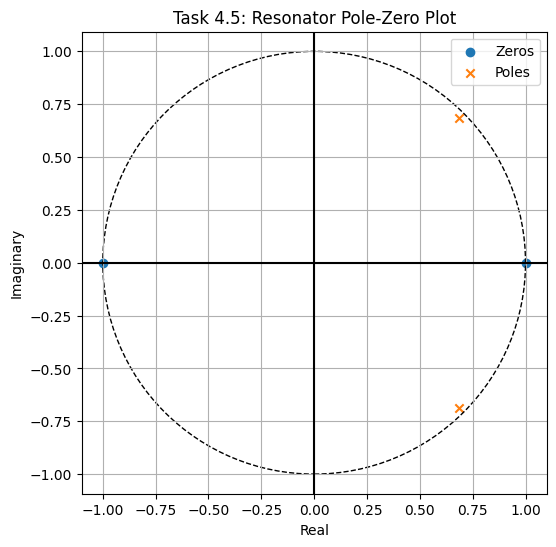

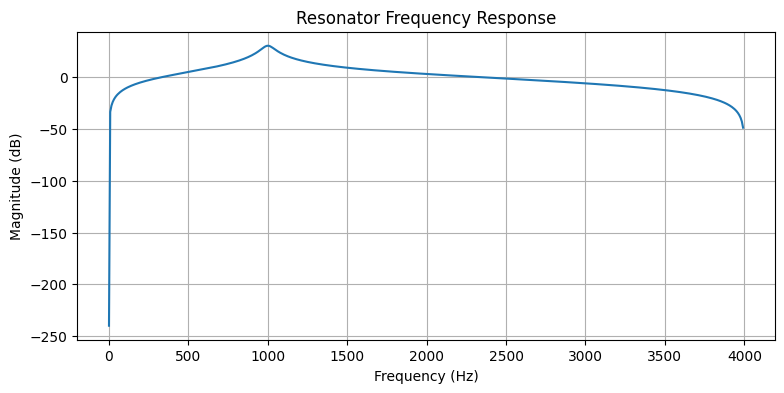

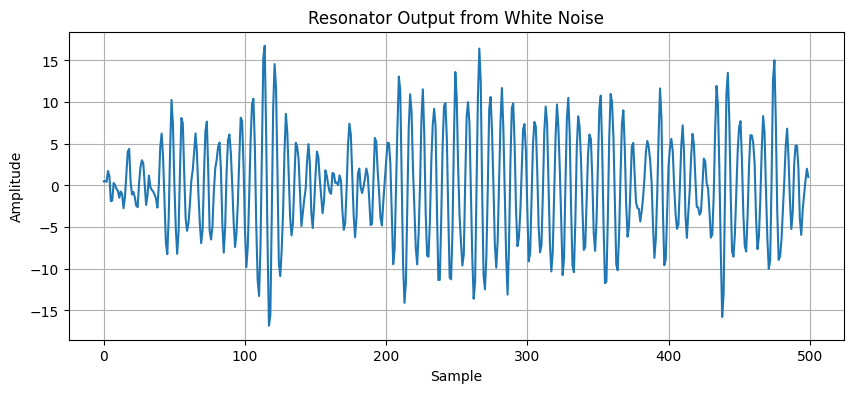

Resonator design completed.


In [48]:
# TASK 4.5: DESIGN A DIGITAL RESONATOR

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

fs = 8000
f0 = 1000
r = 0.97

theta = 2*np.pi*f0/fs

# Zeros at +1 and -1
b = [1, 0, -1]

# Poles
a = [1, -2*r*np.cos(theta), r**2]

# Find poles and zeros
zeros = np.roots(b)
poles = np.roots(a)

print("Zeros:", zeros)
print("Poles:", poles)

# Pole-zero plot
plt.figure(figsize=(6, 6))
plt.scatter(np.real(zeros), np.imag(zeros),
            marker='o', label="Zeros")
plt.scatter(np.real(poles), np.imag(poles),
            marker='x', label="Poles")

circle = plt.Circle((0, 0), 1, fill=False, linestyle='--')
plt.gca().add_patch(circle)

plt.axhline(0, color='black')
plt.axvline(0, color='black')
plt.title("Task 4.5: Resonator Pole-Zero Plot")
plt.xlabel("Real")
plt.ylabel("Imaginary")
plt.legend()
plt.grid()
plt.axis('equal')
plt.show()

# Frequency response
w, h = signal.freqz(b, a, fs=fs)

plt.figure(figsize=(9, 4))
plt.plot(w, 20*np.log10(np.abs(h) + 1e-12))
plt.title("Resonator Frequency Response")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude (dB)")
plt.grid()
plt.show()

# Apply resonator to white noise
np.random.seed(42)
noise = np.random.randn(8000)
output = signal.lfilter(b, a, noise)

plt.figure(figsize=(10, 4))
plt.plot(output[:500])
plt.title("Resonator Output from White Noise")
plt.xlabel("Sample")
plt.ylabel("Amplitude")
plt.grid()
plt.show()

print("Resonator design completed.")

WEEK 4 – PRE-LAB QUESTIONS AND ANSWERS

1. Find the poles of the transfer function:

[
H(z)=\frac{1}{1-0.9z^{-1}+0.81z^{-2}}
]

The poles are the roots of:

[
z^2-0.9z+0.81=0
]

The poles are complex conjugates with magnitude 0.9. Since their magnitudes are less than 1, the system is stable.

2. Find the partial fraction expansion of:

[
X(z)=\frac{1}{(1-0.5z^{-1})(1-0.25z^{-1})}
]

The partial fraction expansion is:

[
X(z)=\frac{2}{1-0.5z^{-1}}-\frac{1}{1-0.25z^{-1}}
]

WEEK 4 – ANALYSIS QUESTIONS AND ANSWERS

1. What happens when the pole radius increases?

When the pole radius increases towards 1, the frequency response becomes sharper and narrower, producing a stronger resonance.

2. What happens when a pole lies on the unit circle?

A pole on the unit circle produces a non-decaying oscillation. The system is not BIBO stable.

3. Why are zeros placed at z = +1 and z = -1 in the resonator design?

The zeros at z = +1 and z = -1 suppress the DC frequency and Nyquist frequency, respectively, allowing the system to behave as a band-pass resonator.

4. How can the stability of a digital system be determined using poles?

A digital system is BIBO stable if all its poles lie strictly inside the unit circle. If any pole lies on or outside the unit circle, the system is not BIBO stable.

WEEK 4 – CONCLUSION

This laboratory provided practical knowledge of the Z-transform, poles and zeros, inverse Z-transform and frequency response of digital systems. The experiments demonstrated how pole locations affect system stability and frequency characteristics. The resonator design also showed how digital filters can be used to select specific frequency components. These concepts are essential in the analysis and design of digital signal processing systems.